## 1. 메뉴 2개, 재료 3개, 최대 주문 대기 수 2개 (Reward 초기조건 그대로)

Episode [50/2000] | Total Reward: -30.80
Episode [100/2000] | Total Reward: -37.80
Episode [150/2000] | Total Reward: -22.70
Episode [200/2000] | Total Reward: -26.80
Episode [250/2000] | Total Reward: -22.50
Episode [300/2000] | Total Reward: -20.60
Episode [350/2000] | Total Reward: -20.70
Episode [400/2000] | Total Reward: -20.70
Episode [450/2000] | Total Reward: -20.60
Episode [500/2000] | Total Reward: -20.80
Episode [550/2000] | Total Reward: -20.50
Episode [600/2000] | Total Reward: -20.80
Episode [650/2000] | Total Reward: -20.60
Episode [700/2000] | Total Reward: -22.60
Episode [750/2000] | Total Reward: -20.40
Episode [800/2000] | Total Reward: -20.70
Episode [850/2000] | Total Reward: -20.80
Episode [900/2000] | Total Reward: -20.80
Episode [950/2000] | Total Reward: -20.60
Episode [1000/2000] | Total Reward: -20.80
Episode [1050/2000] | Total Reward: -20.70
Episode [1100/2000] | Total Reward: -20.70
Episode [1150/2000] | Total Reward: -20.70
Episode [1200/2000] | Total Rew

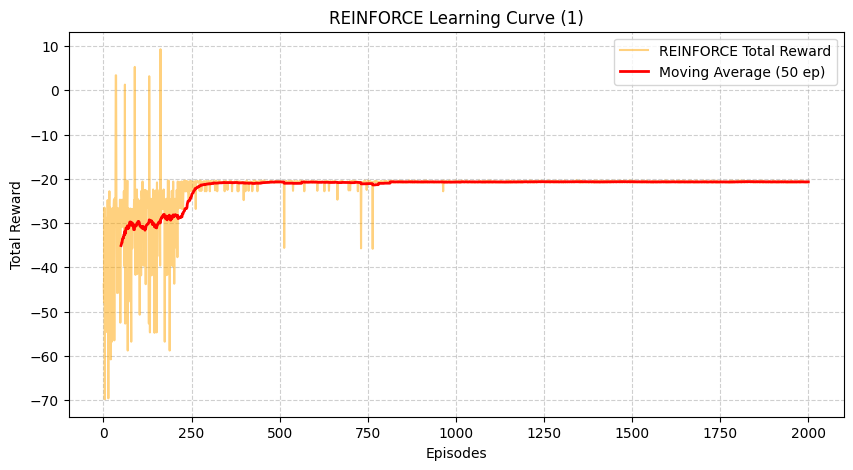

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 2

        # State: [d, c, p, m1, t1, m2, t2] = 7 dim
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        self.observation_space = spaces.Box(low=0.0, high=1.0, shape=(7,), dtype=np.float32)
        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough (d), 2: Add Cheese (c), 3: Add Pepperoni (p), 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0], # Cheese Pizza: Dough + Cheese
            2: [1.0, 1.0, 1.0]  # Pepperoni Pizza: Dough + Cheese + Pepperoni
        }

        self.reset()

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32) # [d, c, p]
        self.orders = []

        # Initialize 2 orders with timer 4~8 steps
        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = np.random.choice([1, 2]) # Cheese or Pepperoni
            timer = np.random.randint(4, 9)     # 4 to 8 steps
            self.orders.append({'menu_id': menu_id, 'timer': timer})

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 8.0)
            else:
                obs.append(0.0)
                obs.append(0.0)
        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1 # Every action penalty
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1: # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            else:
                self.counter[0] = 1.0
        elif action == 2: # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough first)
            else:
                self.counter[1] = 1.0
        elif action == 3: # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough & cheese first)
            else:
                self.counter[2] = 1.0
        elif action == 4: # Serve (FIFO based on orders[0])
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 20.0 # Correct serve
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on correct serve
                else:
                    reward -= 15.0 # Incorrect serve penalty
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on incorrect serve
                    # Orders kept as is, timer decreases below in timer loop
            else:
                reward -= 1.0 # Serve with no orders

        # 2. Timer Update & Timeout Check for Waiting Orders
        orders_to_remove = []
        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 10.0 # Timeout penalty
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        # Episode termination condition: All orders completed or canceled
        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}

# 2. Define Policy Network
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x

# 3. REINFORCE Training Function with History Tracking
def train_reinforce(env, policy_net, optimizer, num_episodes=2000, gamma=0.99):
    reward_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()
        log_probs = []
        rewards = []

        done = False
        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)
            probs = policy_net(state_tensor)

            m = torch.distributions.Categorical(probs)
            action = m.sample()

            log_probs.append(m.log_prob(action))

            next_state, reward, terminated, truncated, info = env.step(action.item())
            done = terminated or truncated

            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)
        reward_history.append(total_reward)

        # Calculate returns (Discounted cumulative rewards)
        returns = []
        G = 0
        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Normalize returns for stability
        if len(returns) > 1 and returns.std() > 0:
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        # Policy gradient update
        optimizer.zero_grad()
        policy_loss = []
        for log_prob, G in zip(log_probs, returns):
            policy_loss.append(-log_prob * G)

        loss = torch.sum(torch.stack(policy_loss))
        loss.backward()
        optimizer.step()

        if (episode + 1) % 50 == 0:
            print(f"Episode [{episode+1}/{num_episodes}] | Total Reward: {total_reward:.2f}")

    return reward_history

# 4. Execution
env = PizzaShopEnv()
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
optimizer = optim.Adam(policy_net.parameters(), lr=0.001)

rewards_history = train_reinforce(env, policy_net, optimizer, num_episodes=2000)

# 5. Visualization
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(rewards_history) + 1), rewards_history, label='REINFORCE Total Reward', color='orange', alpha=0.5)

window_size = 50
if len(rewards_history) >= window_size:
    moving_avg = np.convolve(rewards_history, np.ones(window_size)/window_size, mode='valid')
    plt.plot(range(window_size, len(rewards_history) + 1), moving_avg, label=f'Moving Average ({window_size} ep)', color='red', linewidth=2)

plt.title('REINFORCE Learning Curve (1)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**현상**: 초기 보상 체계 하에서 에이전트가 피자 제작을 학습하지 못하고 -20점(주문 2개 타임아웃 페널티 -10x2)에 고정되어 수렴.

**원인**: 오답 페널티(-15)나 조작 감점(-2)보다 가만히 있다가 타임아웃(-10)으로 끝내는 것이 손실이 더 적어, 에이전트가 '타임아웃 대기 꼼수'를 최적 전략으로 오인함.

**결론 및 시사점**: 에이전트가 위험을 감수하고 피자를 만들도록 타임아웃 페널티와 성공 보상 간의 수치적 균형(보상 구조)을 재조정해야 함.
보상 조정을 통해 적극적인 행동을 유도하는 동시에, 향후 환경 복잡도에 대응하기 위한 알고리즘 고도화 검토 필요.

####
## 2. 메뉴 2개, 재료 3개, 최대 주문 대기 수 2개 (Reward 타임아웃 페널티 -50으로 변경)

Episode [50/2000] | Total Reward: -102.60
Episode [100/2000] | Total Reward: -104.80
Episode [150/2000] | Total Reward: -106.80
Episode [200/2000] | Total Reward: -102.60
Episode [250/2000] | Total Reward: -100.70
Episode [300/2000] | Total Reward: -100.80
Episode [350/2000] | Total Reward: -102.80
Episode [400/2000] | Total Reward: -100.80
Episode [450/2000] | Total Reward: -100.80
Episode [500/2000] | Total Reward: -100.70
Episode [550/2000] | Total Reward: -100.70
Episode [600/2000] | Total Reward: -100.50
Episode [650/2000] | Total Reward: -100.70
Episode [700/2000] | Total Reward: -100.60
Episode [750/2000] | Total Reward: -100.70
Episode [800/2000] | Total Reward: -100.60
Episode [850/2000] | Total Reward: -100.70
Episode [900/2000] | Total Reward: -100.50
Episode [950/2000] | Total Reward: -100.70
Episode [1000/2000] | Total Reward: -100.70
Episode [1050/2000] | Total Reward: -100.70
Episode [1100/2000] | Total Reward: -100.70
Episode [1150/2000] | Total Reward: -100.80
Episode 

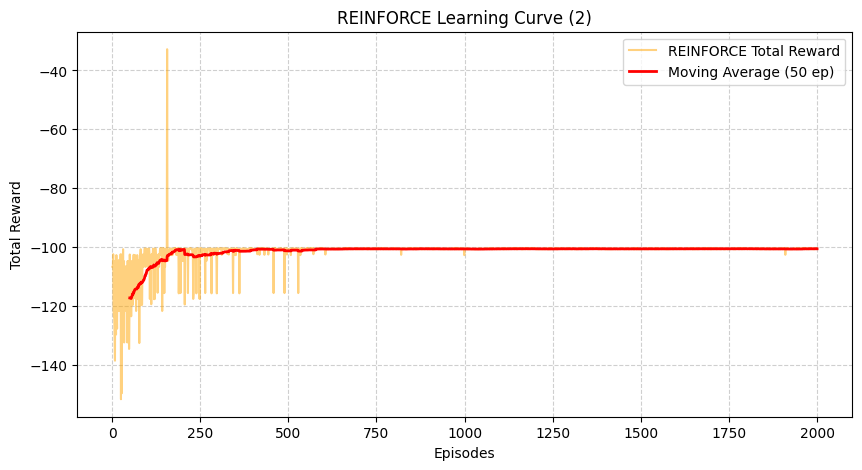

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 2

        # State: [d, c, p, m1, t1, m2, t2] = 7 dim
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        self.observation_space = spaces.Box(low=0.0, high=1.0, shape=(7,), dtype=np.float32)
        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough (d), 2: Add Cheese (c), 3: Add Pepperoni (p), 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0], # Cheese Pizza: Dough + Cheese
            2: [1.0, 1.0, 1.0]  # Pepperoni Pizza: Dough + Cheese + Pepperoni
        }

        self.reset()

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32) # [d, c, p]
        self.orders = []

        # Initialize 2 orders with timer 4~8 steps
        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = np.random.choice([1, 2]) # Cheese or Pepperoni
            timer = np.random.randint(4, 9)     # 4 to 8 steps
            self.orders.append({'menu_id': menu_id, 'timer': timer})

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 8.0)
            else:
                obs.append(0.0)
                obs.append(0.0)
        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1 # Every action penalty
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1: # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            else:
                self.counter[0] = 1.0
        elif action == 2: # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough first)
            else:
                self.counter[1] = 1.0
        elif action == 3: # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough & cheese first)
            else:
                self.counter[2] = 1.0
        elif action == 4: # Serve (FIFO based on orders[0])
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 20.0 # Correct serve
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on correct serve
                else:
                    reward -= 15.0 # Incorrect serve penalty
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on incorrect serve
            else:
                reward -= 1.0 # Serve with no orders

        # 2. Timer Update & Timeout Check for Waiting Orders
        orders_to_remove = []
        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0 # ⭐ Timeout penalty (-10 -> -50)
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        # Episode termination condition: All orders completed or canceled
        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}

# 2. Define Policy Network
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x

# 3. REINFORCE Training Function with History Tracking
def train_reinforce(env, policy_net, optimizer, num_episodes=2000, gamma=0.99):
    reward_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()
        log_probs = []
        rewards = []

        done = False
        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)
            probs = policy_net(state_tensor)

            m = torch.distributions.Categorical(probs)
            action = m.sample()

            log_probs.append(m.log_prob(action))

            next_state, reward, terminated, truncated, info = env.step(action.item())
            done = terminated or truncated

            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)
        reward_history.append(total_reward)

        # Calculate returns (Discounted cumulative rewards)
        returns = []
        G = 0
        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Normalize returns for stability
        if len(returns) > 1 and returns.std() > 0:
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        # Policy gradient update
        optimizer.zero_grad()
        policy_loss = []
        for log_prob, G in zip(log_probs, returns):
            policy_loss.append(-log_prob * G)

        loss = torch.sum(torch.stack(policy_loss))
        loss.backward()
        optimizer.step()

        if (episode + 1) % 50 == 0:
            print(f"Episode [{episode+1}/{num_episodes}] | Total Reward: {total_reward:.2f}")

    return reward_history

# 4. Execution
env = PizzaShopEnv()
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
optimizer = optim.Adam(policy_net.parameters(), lr=0.001)

rewards_history = train_reinforce(env, policy_net, optimizer, num_episodes=2000)

# 5. Visualization
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(rewards_history) + 1), rewards_history, label='REINFORCE Total Reward', color='orange', alpha=0.5)

window_size = 50
if len(rewards_history) >= window_size:
    moving_avg = np.convolve(rewards_history, np.ones(window_size)/window_size, mode='valid')
    plt.plot(range(window_size, len(rewards_history) + 1), moving_avg, label=f'Moving Average ({window_size} ep)', color='red', linewidth=2)

plt.title('REINFORCE Learning Curve (2)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**현상**: 타임아웃 페널티를 -50으로 상향한 결과, 에이전트가 학습을 거듭해도 점수가 오르지 않고 -100점(주문 2개 타임아웃 페널티 -50x2)에 완전히 고정되어 수렴.

**원인**: 타임아웃 페널티가 지나치게 과도해진 반면, 정답 서빙 보상(+20)은 여전히 낮아 피자를 만들다 실패할 때의 리스크가 너무 커짐. 에이전트가 "어떤 행동을 하든 정답을 맞히기는 어렵고 가만히 있어도 큰 감점이니, 아예 피자 제작을 포기하고 타임아웃 확정 루트로 도망치자"는 더 극단적인 방어적 꼼수를 학습함.

**결론 및 시사점**: 페널티만 일방적으로 높이는 방식은 에이전트를 적극적으로 움직이게 하지 못하고 오히려 학습을 완전히 마비시킴. 올바른 행동을 유도하려면 페널티 강화뿐만 아니라 정답 서빙 보상을 함께 조정하여 성공의 기대 가치를 확실히 높여주어야 함.

####
## 3. 메뉴 2개, 재료 3개, 최대 주문 대기 수 2개 (정확한 피자 서빙 Reward +150으로 향상)

Episode [50/2000] | Total Reward: -121.80
Episode [100/2000] | Total Reward: -106.60
Episode [150/2000] | Total Reward: -100.80
Episode [200/2000] | Total Reward: -100.60
Episode [250/2000] | Total Reward: -100.70
Episode [300/2000] | Total Reward: -104.60
Episode [350/2000] | Total Reward: -102.70
Episode [400/2000] | Total Reward: -100.50
Episode [450/2000] | Total Reward: -100.70
Episode [500/2000] | Total Reward: -100.60
Episode [550/2000] | Total Reward: -100.50
Episode [600/2000] | Total Reward: -100.50
Episode [650/2000] | Total Reward: -102.70
Episode [700/2000] | Total Reward: -100.50
Episode [750/2000] | Total Reward: -100.80
Episode [800/2000] | Total Reward: -100.80
Episode [850/2000] | Total Reward: -100.50
Episode [900/2000] | Total Reward: -100.80
Episode [950/2000] | Total Reward: -100.60
Episode [1000/2000] | Total Reward: -100.80
Episode [1050/2000] | Total Reward: -100.50
Episode [1100/2000] | Total Reward: -100.70
Episode [1150/2000] | Total Reward: -100.70
Episode 

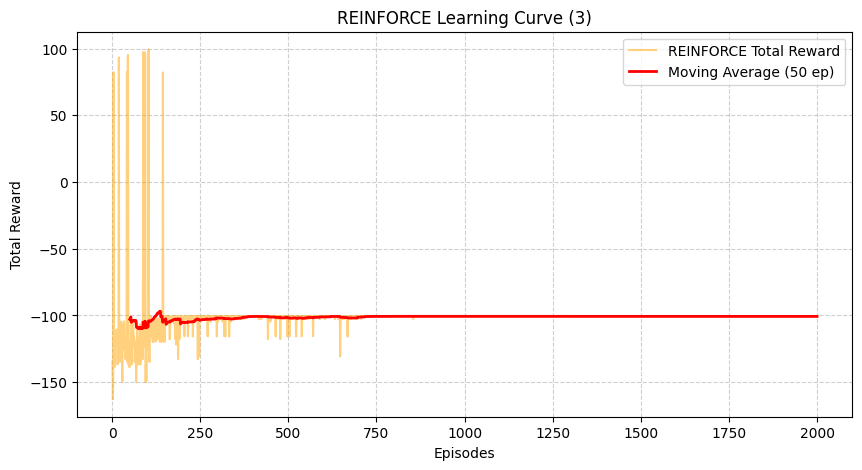

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 2

        # State: [d, c, p, m1, t1, m2, t2] = 7 dim
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        self.observation_space = spaces.Box(low=0.0, high=1.0, shape=(7,), dtype=np.float32)
        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough (d), 2: Add Cheese (c), 3: Add Pepperoni (p), 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0], # Cheese Pizza: Dough + Cheese
            2: [1.0, 1.0, 1.0]  # Pepperoni Pizza: Dough + Cheese + Pepperoni
        }

        self.reset()

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32) # [d, c, p]
        self.orders = []

        # Initialize 2 orders with timer 4~8 steps
        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = np.random.choice([1, 2]) # Cheese or Pepperoni
            timer = np.random.randint(4, 9)     # 4 to 8 steps
            self.orders.append({'menu_id': menu_id, 'timer': timer})

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 8.0)
            else:
                obs.append(0.0)
                obs.append(0.0)
        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1 # Every action penalty
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1: # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            else:
                self.counter[0] = 1.0
        elif action == 2: # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough first)
            else:
                self.counter[1] = 1.0
        elif action == 3: # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough & cheese first)
            else:
                self.counter[2] = 1.0
        elif action == 4: # Serve (FIFO based on orders[0])
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 150.0 # ⭐ Correct serve reward (+20 -> +150)
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on correct serve
                else:
                    reward -= 15.0 # Incorrect serve penalty
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on incorrect serve
            else:
                reward -= 1.0 # Serve with no orders

        # 2. Timer Update & Timeout Check for Waiting Orders
        orders_to_remove = []
        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0 # ⭐ Timeout penalty (-10 -> -50):
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        # Episode termination condition: All orders completed or canceled
        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}

# 2. Define Policy Network
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x

# 3. REINFORCE Training Function with History Tracking
def train_reinforce(env, policy_net, optimizer, num_episodes=2000, gamma=0.99):
    reward_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()
        log_probs = []
        rewards = []

        done = False
        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)
            probs = policy_net(state_tensor)

            m = torch.distributions.Categorical(probs)
            action = m.sample()

            log_probs.append(m.log_prob(action))

            next_state, reward, terminated, truncated, info = env.step(action.item())
            done = terminated or truncated

            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)
        reward_history.append(total_reward)

        # Calculate returns (Discounted cumulative rewards)
        returns = []
        G = 0
        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Normalize returns for stability
        if len(returns) > 1 and returns.std() > 0:
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        # Policy gradient update
        optimizer.zero_grad()
        policy_loss = []
        for log_prob, G in zip(log_probs, returns):
            policy_loss.append(-log_prob * G)

        loss = torch.sum(torch.stack(policy_loss))
        loss.backward()
        optimizer.step()

        if (episode + 1) % 50 == 0:
            print(f"Episode [{episode+1}/{num_episodes}] | Total Reward: {total_reward:.2f}")

    return reward_history

# 4. Execution
env = PizzaShopEnv()
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
optimizer = optim.Adam(policy_net.parameters(), lr=0.001)

rewards_history = train_reinforce(env, policy_net, optimizer, num_episodes=2000)

# 5. Visualization
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(rewards_history) + 1), rewards_history, label='REINFORCE Total Reward', color='orange', alpha=0.5)

window_size = 50
if len(rewards_history) >= window_size:
    moving_avg = np.convolve(rewards_history, np.ones(window_size)/window_size, mode='valid')
    plt.plot(range(window_size, len(rewards_history) + 1), moving_avg, label=f'Moving Average ({window_size} ep)', color='red', linewidth=2)

plt.title('REINFORCE Learning Curve (3)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**현상**: 타임아웃 페널티를 강화하고(-50), 정답 서빙 보상을 +20에서 +150까지 대폭 상향했음에도 불구하고, 학습이 진행될수록 에이전트가 점수를 높이지 못한 채 주문 2개 타임아웃 손실에 해당하는 -100점 부근에 완전히 고정되어 수렴함.

**원인**:
1. 초기 무작위 탐색 단계에서 에이전트가 순서 제약(도우 -> 치즈 -> 페퍼로니 -> 서빙)을 우연히 정확히 맞혀 성공 보상을 획득할 확률이 극도로 낮음.
2. 학습 초기에 무작위 행동으로 인한 감점 누적 때문에, 정책 신경망의 가중치가 "불확실한 성공을 노리기보다 아무것도 하지 않고 손실을 감수하는 것"이 안전하다는 방향으로 완전히 굳어져 버림.
3. 보상 수치(성공 보상)를 아무리 높여도 에이전트가 그 보상 지점에 도달할 수 있는 '경로(Trajectory)'를 스스로 탐색하지 못한다면 수치 조정만으로는 학습 부진을 해결할 수 없음.

**결론 및 시사점**: 순수 정책 기반 알고리즘인 REINFORCE는 높은 분산과 탐색 능력 부족으로 인해, 엄격한 순서 제약과 희소 보상(Sparse Reward)이 존재하는 복잡한 MDP 환경에서 전역 최적점(Global Optimum)을 찾는 데 실패함을 실증적으로 입증함.

**알고리즘 전환 당위성**: 단순한 보상 튜닝이나 페널티 조정을 넘어, 가치 함수(Critic)를 도입해 상태의 가치를 안정적으로 평가하고 샘플 효율성을 극대화할 수 있는 PPO(Proximal Policy Optimization) 또는 Actor-Critic 계열의 알고리즘으로의 전환이 필수적임.   